<a href="https://colab.research.google.com/github/Mgourson/IS/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, accuracy_score

%matplotlib inline

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:
# Import data from the AdviseInvest historical dataset
csv_url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv'
df = pd.read_csv(csv_url)

# Describe/profile the dataframe
print("=== DataFrame Info ===")
print(df.info())

print("\n=== Descriptive Statistics ===")
display(df.describe(include='all'))

# Look for missing values
print("\n=== Missing Values Count ===")
print(df.isnull().sum())

# Look for duplicates
print("\n=== Duplicate Records ===")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB
None

=== Descriptive Statistics ===


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000



=== Missing Values Count ===
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

=== Duplicate Records ===
Number of duplicate rows: 3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response:
1.1. A few things stood out in the initial preview of the dataset. First, there were some unusual outliers, including a minimum income of -65,600, a maximum age of 132, and a maximum num_accts of 3,345, which are all unrealistic or highly unusual values. I also noticed that new_car has 2 missing values and there are 3 duplicate rows. Another issue is that female was imported as an object and has 3 unique values instead of 2, which could mean the data was labeled inconsistently. Lastly, the product column stood out because its value is determined after the target event, answered, occurs, which could cause data leakage if we used it to predict whether a customer answers.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:
# 2.4 Clean up the data and put it in a new dataframe named "df_clean"
# Start with a copy of the original dataframe
df_clean = df.copy()

# Drop duplicates
df_clean = df_clean.drop_duplicates()

# 2.1 Check for and remove any outliers
# Remove negative income values
df_clean = df_clean[df_clean['income'] >= 0]

# Remove unrealistic age outliers (e.g., keeping age <= 100)
df_clean = df_clean[df_clean['age'] <= 100]

# Remove unrealistic num_accts outliers (e.g., keeping num_accts <= 100)
df_clean = df_clean[df_clean['num_accts'] <= 100]

# 2.2 Address missing data in 'new_car'
# Since there are only 2 missing values, we can safely drop these rows
df_clean = df_clean.dropna(subset=['new_car'])

# 2.3 Remove unhelpful variables or post-event variables
# customer_id is a random identifier; product is recorded AFTER they answer
df_clean = df_clean.drop(columns=['customer_id', 'product'])

# Profile the cleaned dataframe to verify the results
print("=== Cleaned DataFrame Info ===")
print(df_clean.info())

print("\n=== Cleaned Descriptive Statistics ===")
display(df_clean.describe(include='all'))

print("\n=== Remaining Missing Values ===")
print(df_clean.isnull().sum())

=== Cleaned DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
Index: 29495 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29495 non-null  int64  
 1   income          29495 non-null  int64  
 2   female          29495 non-null  object 
 3   age             29495 non-null  int64  
 4   job             29495 non-null  int64  
 5   num_dependents  29495 non-null  int64  
 6   rent            29495 non-null  int64  
 7   own_res         29495 non-null  int64  
 8   new_car         29495 non-null  float64
 9   chk_acct        29495 non-null  int64  
 10  sav_acct        29495 non-null  int64  
 11  num_accts       29495 non-null  int64  
 12  mobile          29495 non-null  int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 3.2+ MB
None

=== Cleaned Descriptive Statistics ===


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
count,29495.000000,29495.000000,29495,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000
unique,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,27896,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.546669,33776.323445,NaN,34.770232,1.915443,1.141041,0.210375,0.681132,0.240787,1.468215,0.956365,2.345313,0.091100
std,0.497826,29374.630821,NaN,11.354514,0.658239,0.348070,0.407582,0.466046,0.427568,1.234684,1.483834,1.200659,0.287756
min,0.000000,2760.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
75%,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000



=== Remaining Missing Values ===
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response:
2.5 To clean the outliers, I removed rows where income was negative since those values were invalid. I also removed rows where age was over 100 and where num_accts was over 100 because those values were unrealistic or extremely unusual. For the missing data in new_car, there were only 2 missing values out of almost 29,500 records. I decided to drop those rows because losing just 2 records would have almost no impact on the dataset and would avoid introducing any potential bias from filling in the missing values.

2.6 I removed customer_id and product from the dataset. The customer_id column was just a unique identifier and didn't provide any useful information for predicting whether someone would answer a call. Keeping it could also cause the model to overfit. I removed product because that information is only determined after a customer answers the call. Including it would cause data leakage since it could reveal whether the customer answered, making the model unreliable for predicting who will answer before a call is made.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [4]:
# Change 'answered' to a boolean (True/False)
df_clean['answered'] = df_clean['answered'].astype(bool)

# List of columns to convert to integer types
# 'female' is currently object/string and contains some noise, so we keep it or clean it later
int_cols = [
    'income', 'age', 'job', 'num_dependents', 'rent',
    'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile'
]

# Convert identified columns to integer
for col in int_cols:
    df_clean[col] = df_clean[col].astype(int)

# Verify the conversion results
print("=== Cleaned & Standardized DataFrame Info ===")
print(df_clean.info())
print("\n=== Preview Data ===")
display(df_clean.head())

=== Cleaned & Standardized DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
Index: 29495 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   answered        29495 non-null  bool  
 1   income          29495 non-null  int64 
 2   female          29495 non-null  object
 3   age             29495 non-null  int64 
 4   job             29495 non-null  int64 
 5   num_dependents  29495 non-null  int64 
 6   rent            29495 non-null  int64 
 7   own_res         29495 non-null  int64 
 8   new_car         29495 non-null  int64 
 9   chk_acct        29495 non-null  int64 
 10  sav_acct        29495 non-null  int64 
 11  num_accts       29495 non-null  int64 
 12  mobile          29495 non-null  int64 
dtypes: bool(1), int64(11), object(1)
memory usage: 3.0+ MB
None

=== Preview Data ===


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [5]:
# Convert at least 3 variables to categorical
cat_cols = ['job', 'chk_acct', 'sav_acct']

for col in cat_cols:
    df_clean[col] = df_clean[col].astype('category')

# Verify changes
print("=== Cleaned DataFrame Info with Categories ===")
print(df_clean.info())
print("\n=== Category Variable Categories ===")
for col in cat_cols:
    print(f"{col}: {df_clean[col].cat.categories.tolist()}")

=== Cleaned DataFrame Info with Categories ===
<class 'pandas.core.frame.DataFrame'>
Index: 29495 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   answered        29495 non-null  bool    
 1   income          29495 non-null  int64   
 2   female          29495 non-null  object  
 3   age             29495 non-null  int64   
 4   job             29495 non-null  category
 5   num_dependents  29495 non-null  int64   
 6   rent            29495 non-null  int64   
 7   own_res         29495 non-null  int64   
 8   new_car         29495 non-null  int64   
 9   chk_acct        29495 non-null  category
 10  sav_acct        29495 non-null  category
 11  num_accts       29495 non-null  int64   
 12  mobile          29495 non-null  int64   
dtypes: bool(1), category(3), int64(8), object(1)
memory usage: 2.4+ MB
None

=== Category Variable Categories ===
job: [0, 1, 2, 3]
chk_acct: [0, 1, 2, 3]
sav

# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



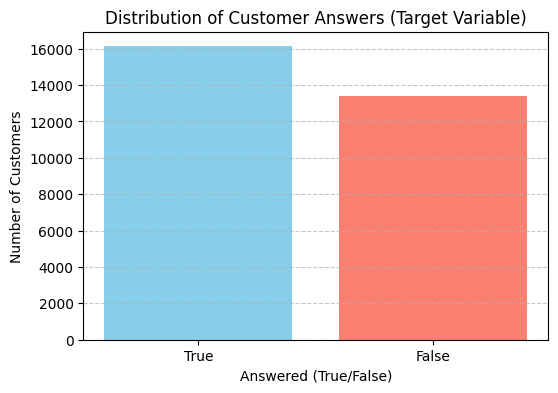

In [6]:
# Chart 3.1: Distribution of the target variable 'answered'
answered_counts = df_clean['answered'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(answered_counts.index.astype(str), answered_counts.values, color=['skyblue', 'salmon'])
plt.title('Distribution of Customer Answers (Target Variable)')
plt.xlabel('Answered (True/False)')
plt.ylabel('Number of Customers')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

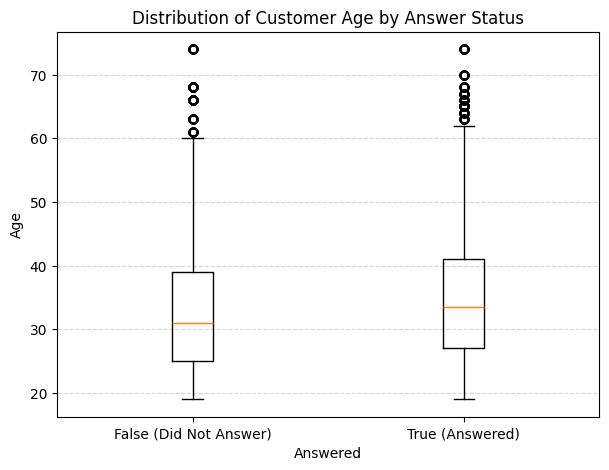

In [8]:
# Chart 3.2: Relationship between Age and Answered
plt.figure(figsize=(7, 5))
data_to_plot = [df_clean[df_clean['answered'] == False]['age'],
                df_clean[df_clean['answered'] == True]['age']]

# Using tick_labels instead of labels to avoid deprecation warnings in modern Matplotlib
plt.boxplot(data_to_plot, tick_labels=['False (Did Not Answer)', 'True (Answered)'])
plt.title('Distribution of Customer Age by Answer Status')
plt.xlabel('Answered')
plt.ylabel('Age')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

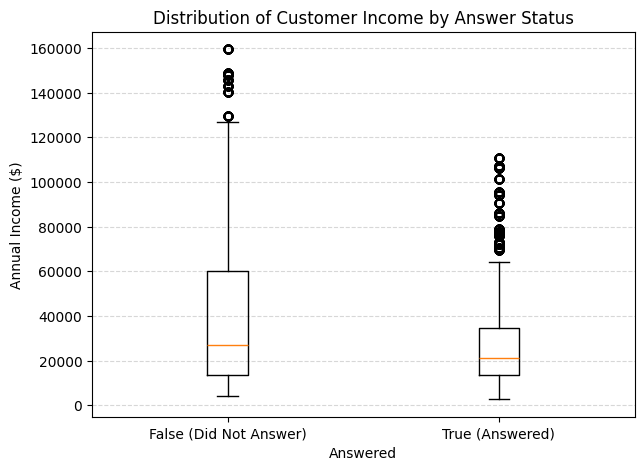

In [9]:
# Chart 3.3: Relationship between Income and Answered
plt.figure(figsize=(7, 5))
data_to_plot = [df_clean[df_clean['answered'] == False]['income'],
                df_clean[df_clean['answered'] == True]['income']]

plt.boxplot(data_to_plot, tick_labels=['False (Did Not Answer)', 'True (Answered)'])
plt.title('Distribution of Customer Income by Answer Status')
plt.xlabel('Answered')
plt.ylabel('Annual Income ($)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

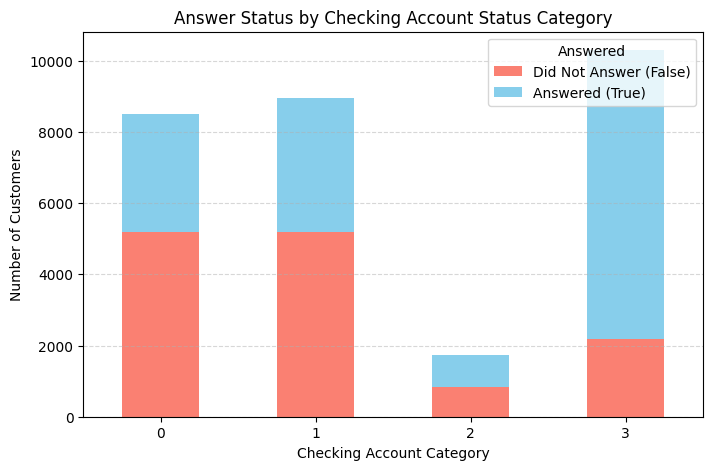

In [10]:
# Chart 3.4: Relationship between Checking Account Status and Answered
chk_answered_counts = pd.crosstab(df_clean['chk_acct'], df_clean['answered'])

chk_answered_counts.plot(kind='bar', stacked=True, figsize=(8, 5), color=['salmon', 'skyblue'])
plt.title('Answer Status by Checking Account Status Category')
plt.xlabel('Checking Account Category')
plt.ylabel('Number of Customers')
plt.legend(['Did Not Answer (False)', 'Answered (True)'], title='Answered')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

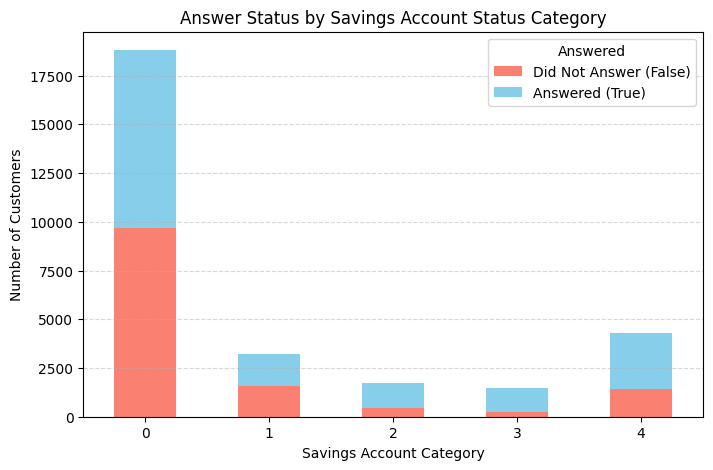

In [11]:
# Chart 3.5: Relationship between Savings Account Status and Answered
sav_answered_counts = pd.crosstab(df_clean['sav_acct'], df_clean['answered'])

sav_answered_counts.plot(kind='bar', stacked=True, figsize=(8, 5), color=['salmon', 'skyblue'])
plt.title('Answer Status by Savings Account Status Category')
plt.xlabel('Savings Account Category')
plt.ylabel('Number of Customers')
plt.legend(['Did Not Answer (False)', 'Answered (True)'], title='Answered')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

### ✍️ Your Response:
3.6. The variables that showed the strongest relationships with answered were chk_acct (checking account status), sav_acct (savings account status), and income. In Chart 3.4, customers in checking account category 3 were much more likely to answer their calls. Chart 3.5 showed that customers in higher savings account categories (2, 3, and 4) also had higher answer rates. Lastly, Chart 3.3 showed that customers who answered their calls generally had a higher median income than those who didn't.

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response:
3.7.age showed a weak relationship with answered, as the boxplots in Chart 3.2 looked very similar for customers who answered and those who didn't. However, I wouldn't remove age just yet because models like Decision Trees can identify patterns that might not be obvious when looking at one variable at a time. For example, age might become a useful predictor when combined with other variables like income or checking account status. Because of this, I think it's worth keeping in the model for now.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# 4.1 Calculate the base probability of answering
total_customers = len(df_clean)
answered_customers = df_clean['answered'].sum()
base_probability = answered_customers / total_customers

print(f"Total Cleaned Customers: {total_customers:,}")
print(f"Customers Who Answered: {answered_customers:,}")
print(f"Base Probability of Answering: {base_probability:.4f} ({base_probability * 100:.2f}%)")

Total Cleaned Customers: 29,495
Customers Who Answered: 16,124
Base Probability of Answering: 0.5467 (54.67%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [13]:
# 4.2: Split the training and testing datasets
# First, clean 'female' column to ensure it is fully numeric (binary) before splitting
df_clean['female'] = pd.to_numeric(df_clean['female'], errors='coerce')
# Fill any NaN values that might have resulted from noise with the mode (0 or 1)
df_clean['female'] = df_clean['female'].fillna(df_clean['female'].mode()[0]).astype(int)

# Separate features (X) and target (y)
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (23596, 12)
X_test shape: (5899, 12)
y_train shape: (23596,)
y_test shape: (5899,)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

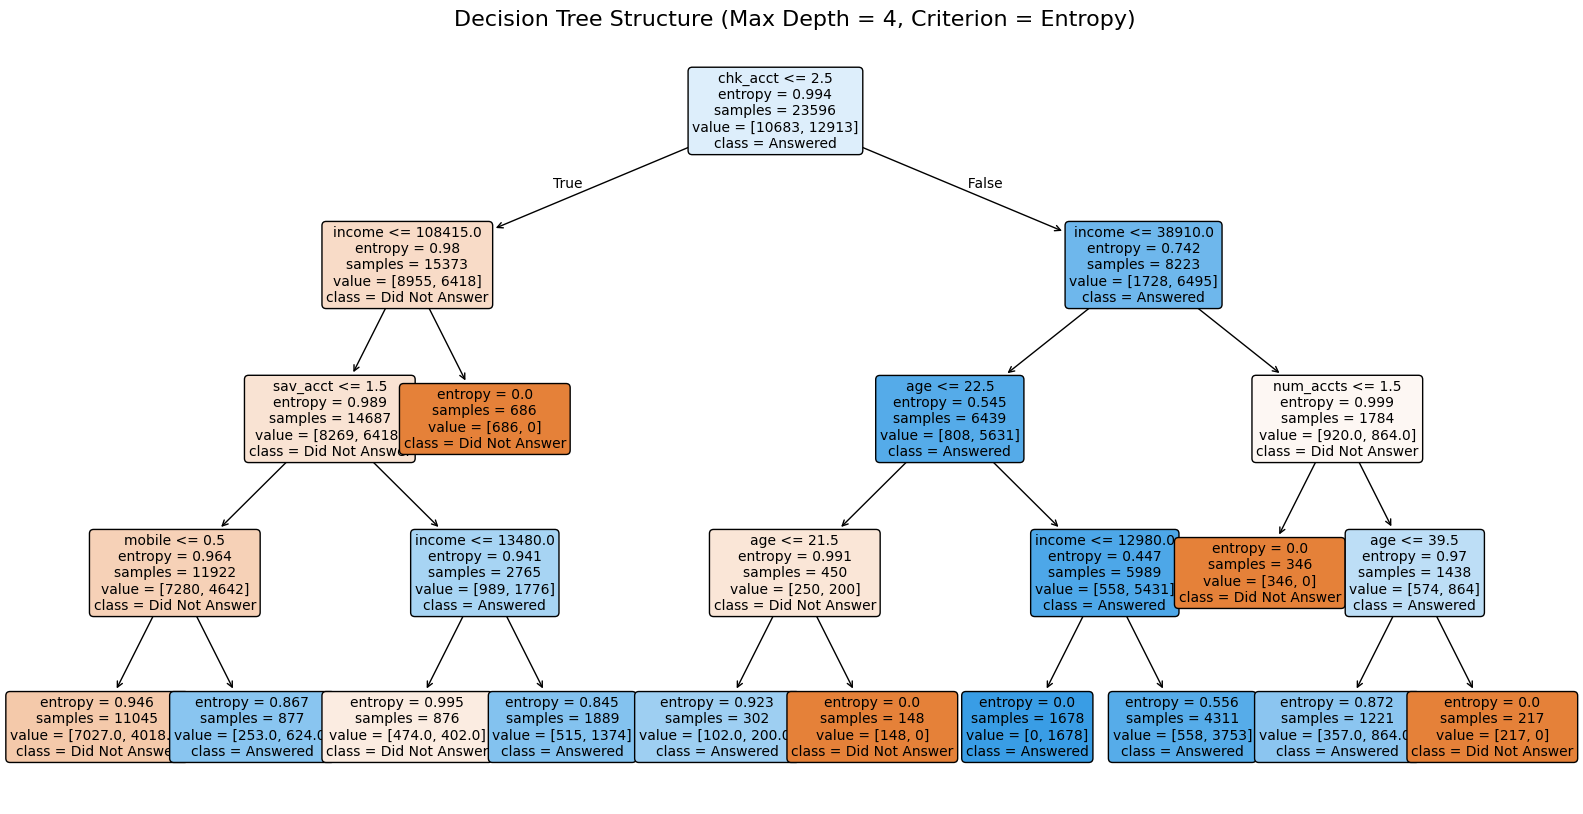

In [14]:
# 4.3: Create and visualize a Decision Tree
# Initialize the model with entropy criterion and max_depth of 4
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Train (fit) the decision tree classifier
clf.fit(X_train, y_train)

# Visualize the tree structure
plt.figure(figsize=(20, 10))
tree.plot_tree(
    clf,
    feature_names=X.columns.tolist(),
    class_names=['Did Not Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 4, Criterion = Entropy)", fontsize=16)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [15]:
# 4.4: Calculate the accuracy of the Decision Tree model on the test set
y_pred = clf.predict(X_test)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Base Probability of Answering: {base_probability:.4f} ({base_probability * 100:.2f}%)")
print(f"Decision Tree Model Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Improvement over Baseline: {(test_accuracy - base_probability) * 100:.2f}%")

Base Probability of Answering: 0.5467 (54.67%)
Decision Tree Model Test Accuracy: 0.7391 (73.91%)
Improvement over Baseline: 19.24%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response:
1. The model has a test accuracy of 73.91%, compared to the baseline probability of 54.67% that a customer will answer without using the model. This is an improvement of 19.24 percentage points, showing that the model can make more accurate predictions than simply relying on the overall answer rate.

2. Yes, I think this is a significant improvement for AdviseInvest. By using the model to identify customers who are more likely to answer, the company could reduce the number of unanswered calls and the amount of time sales representatives spend waiting. This would help representatives use their time more efficiently, improve overall productivity, and potentially lower operating costs.

### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [17]:
# 4.5: Generate the confusion matrix using scikit-learn
cm = confusion_matrix(y_test, y_pred)
print("=== Confusion Matrix ===")
print(cm)

# Calculate individual elements
tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives (Predicted No-Answer, Did Not Answer): {tn}")
print(f"False Positives (Predicted Answer, Did Not Answer): {fp}")
print(f"False Negatives (Predicted No-Answer, Answered): {fn}")
print(f"True Positives (Predicted Answer, Answered): {tp}")

=== Confusion Matrix ===
[[2233  455]
 [1084 2127]]

True Negatives (Predicted No-Answer, Did Not Answer): 2233
False Positives (Predicted Answer, Did Not Answer): 455
False Negatives (Predicted No-Answer, Answered): 1084
True Positives (Predicted Answer, Answered): 2127


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

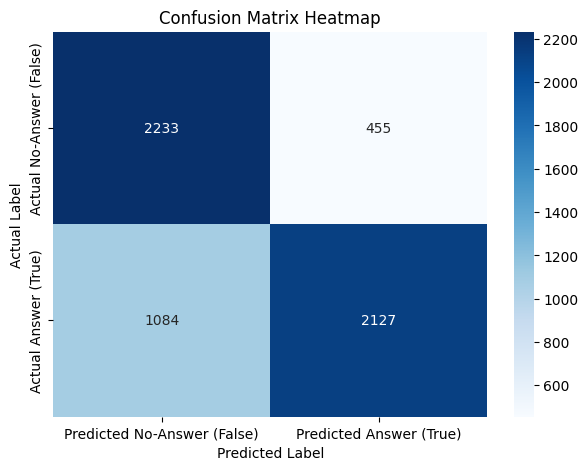

In [18]:
import seaborn as sns

# Configure visual properties for the confusion matrix heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No-Answer (False)", "Predicted Answer (True)"],
    yticklabels=["Actual No-Answer (False)", "Actual Answer (True)"]
)
plt.title("Confusion Matrix Heatmap")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [19]:
# Calculate the financial profit of using the model on the test dataset
# Using the variables calculated from our confusion matrix:
# tn, fp, fn, tp = cm.ravel()

tp_profit = tp * 75
fp_cost = fp * 25
total_model_profit = tp_profit - fp_cost

print("=== Financial Evaluation Using the Model ===")
print(f"True Positives (Predicted Answer, Answered): {tp} -> Profit: ${tp_profit:,}")
print(f"False Positives (Predicted Answer, Did Not Answer): {fp} -> Cost: ${fp_cost:,}")
print(f"Total Expected Profit using the Model: ${total_model_profit:,}")

=== Financial Evaluation Using the Model ===
True Positives (Predicted Answer, Answered): 2127 -> Profit: $159,525
False Positives (Predicted Answer, Did Not Answer): 455 -> Cost: $11,375
Total Expected Profit using the Model: $148,150


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [20]:
# 5.2 Compare to the Default Profit (Calling all customers in the test set)
# Actual answers in the test dataset
actual_answered = y_test.sum()
actual_not_answered = len(y_test) - actual_answered

default_tp_profit = actual_answered * 75
default_fp_cost = actual_not_answered * 25
total_default_profit = default_tp_profit - default_fp_cost

print("=== Default Financial Evaluation (Calling Everyone) ===")
print(f"Actual Answered (Revenue Earned): {actual_answered} -> Profit: ${default_tp_profit:,}")
print(f"Actual Did Not Answer (Loss Incurred): {actual_not_answered} -> Cost: ${default_fp_cost:,}")
print(f"Total Expected Default Profit: ${total_default_profit:,}")

=== Default Financial Evaluation (Calling Everyone) ===
Actual Answered (Revenue Earned): 3211 -> Profit: $240,825
Actual Did Not Answer (Loss Incurred): 2688 -> Cost: $67,200
Total Expected Default Profit: $173,625


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response:
1. The model's expected profit on the test set is $148,150, compared to $173,625 from calling every customer. This means calling everyone would generate $25,475 more in total profit than only calling customers recommended by the model.

2. Yes, I think this is a significant difference, but there are some important factors to consider. Calling everyone requires 5,899 calls, while the model only recommends 2,582 calls (2,127 true positives and 455 false positives). This means the model generates about 85.3% of the total profit while making only 43.8% of the calls. It also increases profit per call from $29.43 to $57.38. Although the model produces less total profit, it makes the calling process much more efficient. This could reduce the workload for sales representatives, lower staffing costs, and allow the company to spend more time reaching customers who are likely to answer.

## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [25]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameters to test
params = {
    'criterion': ['entropy', 'gini'],
    'max_depth': range(3, 15),
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8]
}

# Find the best combination using cross-validation
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Evaluate the tuned model
tuned_clf = grid.best_estimator_
tuned_pred = tuned_clf.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_pred)

print("=== Model Tuning Results ===")
print(f"Initial Accuracy: {test_accuracy:.2%}")
print(f"Tuned Accuracy: {tuned_accuracy:.2%}")
print(f"Improvement: {tuned_accuracy - test_accuracy:.2%}")
print(f"Best Parameters: {grid.best_params_}")

=== Model Tuning Results ===
Initial Accuracy: 73.91%
Tuned Accuracy: 93.20%
Improvement: 19.29%
Best Parameters: {'criterion': 'gini', 'max_depth': 14, 'min_samples_leaf': 1, 'min_samples_split': 2}


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [26]:
# Import new customer data
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(url)

# Clean data using the same steps as Section 2
df_new = df_new.drop_duplicates()
df_new = df_new[
    (df_new['income'] >= 0) &
    (df_new['age'] <= 100) &
    (df_new['num_accts'] <= 100)
].dropna(subset=['new_car'])

# Standardize variables
df_new['female'] = pd.to_numeric(df_new['female'], errors='coerce').fillna(0).astype(int)

int_cols = ['income', 'age', 'job', 'num_dependents', 'rent',
            'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile']

df_new[int_cols] = df_new[int_cols].astype(int)

for col in ['job', 'chk_acct', 'sav_acct']:
    df_new[col] = df_new[col].astype('category')

# Remove columns not used for prediction
X_new = df_new.drop(columns=['customer_id', 'product', 'answered'], errors='ignore')

# Match the training model's feature order
X_new = X_new[X_train.columns]

# Predict using tuned model from 5.3
predictions = tuned_clf.predict(X_new)

# Count yes/no predictions
print("=== New Customer Predictions ===")
print(f"Will Answer (Yes): {(predictions == 1).sum()}")
print(f"Will Not Answer (No): {(predictions == 0).sum()}")
print(f"Total Customers: {len(predictions)}")

=== New Customer Predictions ===
Will Answer (Yes): 493
Will Not Answer (No): 507
Total Customers: 1000


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧 (Im not sure why the text is messed up)
6.1 6.1 The model improved our profit per call, but not our total profit. Calling every customer generated $173,625, while using the model generated $148,150, which is $25,475 less. However, the model achieved about 85.3% of the total profit while making only 43.8% of the calls. It also increased profit per call from $29.43 to $57.38. This shows that even though total profit was lower, the model made the calling process much more efficient.

6.2 AdviseInvest could use this model to identify customers who are more likely to answer their calls and prioritize contacting them first. This would help sales representatives spend less time making unanswered calls and more time speaking with potential customers. The company could also use the model to better manage employee workloads, reduce unnecessary calling costs, and improve overall productivity. Over time, AdviseInvest could continue improving the model with new customer data to make its predictions more accurate.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [27]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1010359 bytes to assignment_10_classification.html
